In [20]:
from pathlib import Path
import shutil

import geopandas as gpd
import matplotlib.pyplot as plt
import osmnx as ox
import pandas as pd
import rasterio
from rasterio.plot import show

PROJECT_ROOT = Path(
    "/Users/modjrin1/Library/CloudStorage/OneDrive-AaltoUniversity/"
    "paper 4 - mobility spain/heat-conditioned-accessibility"
)

RESULTS = PROJECT_ROOT / "outputs" / "accessibility"
SOLWEIG_SUMMARY = PROJECT_ROOT / "outputs" / "solweig" / "summary"
DATA_INTERIM = PROJECT_ROOT / "data" / "interim"

FIGURES = PROJECT_ROOT / "outputs" / "figures"
DOCS_FIGURES = PROJECT_ROOT / "docs" / "figures"

FIGURES.mkdir(parents=True, exist_ok=True)
DOCS_FIGURES.mkdir(parents=True, exist_ok=True)

In [21]:
sensitivity = pd.read_csv(
    RESULTS / "accessibility_sensitivity.csv"
)

access = pd.read_csv(
    RESULTS / "origin_accessibility_lambda_005.csv"
)

routes = pd.read_csv(
    RESULTS / "route_results_lambda_005.csv"
)

G = ox.load_graphml(
    DATA_INTERIM / "sevilla_walk_thermal.graphml"
)

print(sensitivity.head())
print(access.head())

   lambda       mean  median        std  min  max  mean_access_loss_pct
0   0.000  26.326531    27.0  10.859688    5   45              0.000000
1   0.010  21.979592    22.0   9.967635    4   41             16.511628
2   0.025  17.285714    17.0   7.876653    0   36             34.341085
3   0.050  12.673469    13.0   5.821611    0   25             51.860465
4   0.075   9.489796    10.0   4.505194    0   20             63.953488
        origin  normal_access  thermal_access  access_loss  access_loss_pct
0  12705553216             27              16           11        40.740741
1  10215553612             40              19           21        52.500000
2   2448671721             29              19           10        34.482759
3   5959692077             18              10            8        44.444444
4  13031291689             31              13           18        58.064516


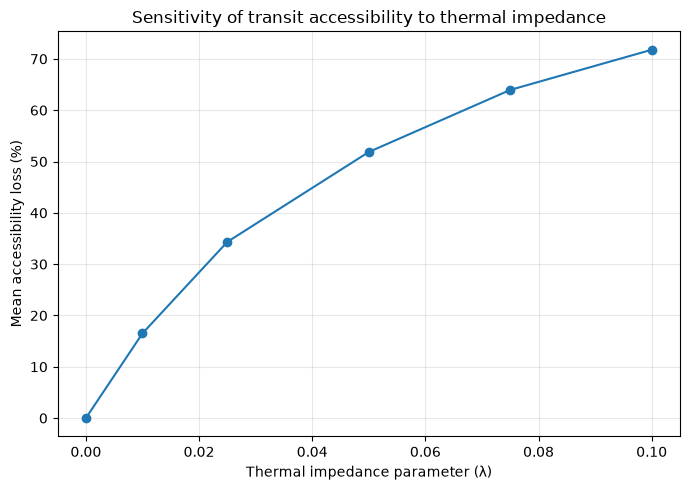

Saved: /Users/modjrin1/Library/CloudStorage/OneDrive-AaltoUniversity/paper 4 - mobility spain/heat-conditioned-accessibility/outputs/figures/sensitivity_curve.png


In [22]:
fig, ax = plt.subplots(figsize=(7, 5))

ax.plot(
    sensitivity["lambda"],
    sensitivity["mean_access_loss_pct"],
    marker="o"
)

ax.set_xlabel("Thermal impedance parameter (λ)")
ax.set_ylabel("Mean accessibility loss (%)")
ax.set_title(
    "Sensitivity of transit accessibility to thermal impedance"
)

ax.grid(alpha=0.3)

plt.tight_layout()

out = FIGURES / "sensitivity_curve.png"

plt.savefig(
    out,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", out)

In [23]:
src = (
    SOLWEIG_SUMMARY
    / "utci_max.preview.png"
)

dst = (
    FIGURES
    / "thermal_environment.png"
)

shutil.copy2(src, dst)

print("Copied thermal figure:", dst)

Copied thermal figure: /Users/modjrin1/Library/CloudStorage/OneDrive-AaltoUniversity/paper 4 - mobility spain/heat-conditioned-accessibility/outputs/figures/thermal_environment.png


In [24]:
for fig in FIGURES.glob("*.png"):
    shutil.copy2(
        fig,
        DOCS_FIGURES / fig.name
    )

print("Files in docs/figures:")

for p in sorted(DOCS_FIGURES.glob("*.png")):
    print("-", p.name)

Files in docs/figures:
- sensitivity_curve.png
- thermal_environment.png
- utci_max.preview.png
